# Limpieza y análisis exploratorio de ventas con Python: Online Retail

## Introducción

Este proyecto analiza registros reales de una tienda online británica, disponibles en el conjunto de datos Online Retail del repositorio UCI.

Los datos contienen 541.909 registros y ocho columnas, con información sobre facturas, productos, cantidades, precios, fechas, clientes y países. El período registrado va desde el 1 de diciembre de 2010 hasta el 9 de diciembre de 2011.

## Objetivo

Preparar los datos para estudiar las ventas de la tienda mediante limpieza, filtrado, análisis estadístico y visualización con Python y pandas.

Antes de realizar cambios, revisaremos los valores faltantes, los registros repetidos, las cancelaciones y las cantidades o precios que requieren atención. Cada decisión de limpieza se documentará para explicar cómo afecta al análisis.

## Fuente de los datos

Chen, D. (2015). Online Retail. UCI Machine Learning Repository.

https://doi.org/10.24432/C5BW33

## 1. Carga de los datos

Leemos el archivo Excel con pandas y mostramos sus primeras filas para reconocer la estructura del conjunto de datos.

Cada fila representa una línea de una factura. Una misma factura puede aparecer en varias filas porque contiene distintos productos; por eso, el número de registros no equivale al número de compras.

In [1]:
import pandas as pd

datos = pd.read_excel("Online Retail.xlsx")

print("Filas y columnas:", datos.shape)
display(datos.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Filas y columnas: (541909, 8)


## 2. Revisión de la calidad de los datos

Antes de limpiar los datos, revisamos los tipos de variables, los valores faltantes y los registros exactamente repetidos. También examinamos cantidades, precios y facturas de cancelación.

Conservamos una copia del conjunto original para poder comparar los datos antes y después de la limpieza.

Esta revisión permite identificar registros que necesitan atención. Un valor negativo o una fila repetida no se considera automáticamente un error: primero debemos revisar su significado.

In [2]:
# Guardamos el original antes de hacer cambios.
datos_originales = datos.copy()
datos_trabajo = datos_originales.copy()

print("1. TAMAÑO DEL CONJUNTO DE DATOS")
print(f"Filas: {datos_trabajo.shape[0]:,}")
print(f"Columnas: {datos_trabajo.shape[1]}\n")

print("2. TIPOS DE DATOS Y VALORES FALTANTES")
resumen = pd.DataFrame({
    "Tipo": datos_trabajo.dtypes.astype(str),
    "Valores faltantes": datos_trabajo.isna().sum(),
    "Porcentaje faltante": (datos_trabajo.isna().mean() * 100).round(2)
})
display(resumen)

print("3. FILAS EXACTAMENTE DUPLICADAS")
print(datos_trabajo.duplicated().sum(), "\n")

print("4. RESUMEN DE CANTIDADES Y PRECIOS")
display(datos_trabajo[["Quantity", "UnitPrice"]].describe())

# Las facturas que empiezan con C corresponden a cancelaciones.
cancelaciones = datos_trabajo["InvoiceNo"].astype("string").str.upper().str.startswith("C", na=False)

print("5. REGISTROS QUE NECESITAN REVISIÓN")
revision = pd.Series({
    "Cancelaciones": cancelaciones.sum(),
    "Cantidad negativa": (datos_trabajo["Quantity"] < 0).sum(),
    "Cantidad cero": (datos_trabajo["Quantity"] == 0).sum(),
    "Precio negativo": (datos_trabajo["UnitPrice"] < 0).sum(),
    "Precio cero": (datos_trabajo["UnitPrice"] == 0).sum(),
    "Sin identificación de cliente": datos_trabajo["CustomerID"].isna().sum()
})
display(revision.to_frame("Número de registros"))

print("6. PERÍODO DE LOS DATOS")
print("Primera fecha:", datos_trabajo["InvoiceDate"].min())
print("Última fecha:", datos_trabajo["InvoiceDate"].max())

print("7. PAÍSES CON MÁS REGISTROS")
display(datos_trabajo["Country"].value_counts().head(10).to_frame("Número de registros"))

,Tipo,Valores faltantes,Porcentaje faltante
InvoiceNo,object,0,0.00
StockCode,object,0,0.00
Description,object,1454,0.27
Quantity,int64,0,0.00
InvoiceDate,datetime64[ns],0,0.00
UnitPrice,float64,0,0.00
CustomerID,float64,135080,24.93
Country,object,0,0.00


,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


,Número de registros
Cancelaciones,9288
Cantidad negativa,10624
Cantidad cero,0
Precio negativo,2
Precio cero,2515
Sin identificación de cliente,135080


,Número de registros
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533
Netherlands,2371
Belgium,2069
Switzerland,2002
Portugal,1519


1. TAMAÑO DEL CONJUNTO DE DATOS
Filas: 541,909
Columnas: 8

2. TIPOS DE DATOS Y VALORES FALTANTES
3. FILAS EXACTAMENTE DUPLICADAS
5268 

4. RESUMEN DE CANTIDADES Y PRECIOS
5. REGISTROS QUE NECESITAN REVISIÓN
6. PERÍODO DE LOS DATOS
Primera fecha: 2010-12-01 08:26:00
Última fecha: 2011-12-09 12:50:00
7. PAÍSES CON MÁS REGISTROS


### Resultados de la revisión inicial

Hay 1.454 registros sin descripción y 135.080 sin cliente (24,93 %). Conservamos inicialmente estos registros para el análisis por fecha y país. Identificamos 5.268 repeticiones adicionales, 9.288 cancelaciones, 10.624 cantidades negativas, dos precios negativos y 2.515 precios iguales a cero. Estos conteos pueden superponerse. Revisamos los casos antes de tomar decisiones.

## 3. Inspección de registros que requieren revisión

Mostramos ejemplos de filas repetidas, precios negativos o iguales a cero, cantidades negativas sin factura de cancelación y valores extremos.

El objetivo es distinguir operaciones comerciales de posibles ajustes o errores antes de construir la tabla para el análisis de ventas.

In [3]:
duplicados = datos_trabajo[datos_trabajo.duplicated(keep=False)]

print("EJEMPLOS DE FILAS EXACTAMENTE REPETIDAS")
display(duplicados.sort_values(["InvoiceNo", "StockCode"]).head(12))

print("\nREGISTROS CON PRECIO NEGATIVO")
display(datos_trabajo[datos_trabajo["UnitPrice"] < 0])

print("\nCANTIDADES NEGATIVAS SIN FACTURA DE CANCELACIÓN")
ajustes = datos_trabajo[(datos_trabajo["Quantity"] < 0) & ~cancelaciones]
display(ajustes.head(10))

print("\nREGISTROS CON PRECIO CERO")
display(datos_trabajo[datos_trabajo["UnitPrice"] == 0].head(10))

print("\nREGISTROS CON LAS MAYORES CANTIDADES")
display(datos_trabajo.nlargest(5, "Quantity"))

print("\nREGISTROS CON LOS MAYORES PRECIOS")
display(datos_trabajo.nlargest(5, "UnitPrice"))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,13256.0,United Kingdom
74614,542504,37413,NaN,5568,2011-01-28 12:03:00,0.00,NaN,United Kingdom
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,2011-10-27 12:26:00,0.21,12901.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom
524602,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom
43702,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,NaN,United Kingdom
43703,C540118,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:57:00,16453.71,NaN,United Kingdom
15016,C537630,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:04:00,13541.33,NaN,United Kingdom


EJEMPLOS DE FILAS EXACTAMENTE REPETIDAS

REGISTROS CON PRECIO NEGATIVO

CANTIDADES NEGATIVAS SIN FACTURA DE CANCELACIÓN

REGISTROS CON PRECIO CERO

REGISTROS CON LAS MAYORES CANTIDADES

REGISTROS CON LOS MAYORES PRECIOS


### Interpretación de los registros inspeccionados

Los dos precios negativos corresponden a ajustes de deuda. Los ejemplos de cantidades negativas sin cancelación tienen precio cero y datos faltantes; podrían ser movimientos de inventario, pero no podemos confirmarlo. Los precios extremos incluyen operaciones manuales y comisiones. Las repeticiones exactas se conservan por ahora porque no contamos con un identificador único de línea.

## 4. Revisión de operaciones extremas y códigos de producto

Buscamos todos los movimientos asociados a los dos productos con mayores cantidades positivas. Esto permite comprobar si también aparecen cantidades negativas para el mismo cliente y producto.

Además, revisamos los códigos que comienzan con una letra para identificar posibles comisiones, descuentos u otros conceptos. Esta selección es una herramienta de inspección; no implica que todos esos códigos deban eliminarse.

In [4]:
# Revisamos los dos productos con cantidades más altas.
casos_extremos = [
    ("23843", 16446),
    ("23166", 12346)
]

for producto, cliente in casos_extremos:
    movimientos = datos_trabajo[
        (datos_trabajo["StockCode"].astype(str) == producto)
        & (datos_trabajo["CustomerID"] == cliente)
    ].sort_values("InvoiceDate").copy()

    movimientos["Importe"] = movimientos["Quantity"] * movimientos["UnitPrice"]

    print(f"\nProducto: {producto} | Cliente: {cliente}")
    display(movimientos)
    print("Suma de cantidades:", movimientos["Quantity"].sum())
    print("Suma de importes:", round(movimientos["Importe"].sum(), 2))

# Inspeccionamos códigos que empiezan con una letra.
codigos_con_letras = datos_trabajo["StockCode"].astype("string").str.match(r"^[A-Za-z]", na=False)

print("\nCÓDIGOS QUE EMPIEZAN CON UNA LETRA")
display(
    datos_trabajo.loc[codigos_con_letras, ["StockCode", "Description"]]
    .drop_duplicates()
    .sort_values("StockCode")
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Importe
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,168469.6
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom,-168469.6


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Importe
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom,77183.6
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom,-77183.6


,StockCode,Description
14514,AMAZONFEE,AMAZON FEE
299982,B,Adjust bad debt
4406,BANK CHARGES,Bank Charges
453999,C2,NaN
1423,C2,CARRIAGE
317508,CRUK,CRUK Commission
141,D,Discount
279258,DCGS0003,ebay
24906,DCGS0003,BOXED GLASS ASHTRAY
170783,DCGS0004,HAYNES CAMPER SHOULDER BAG



Producto: 23843 | Cliente: 16446
Suma de cantidades: 0
Suma de importes: 0.0

Producto: 23166 | Cliente: 12346
Suma de cantidades: 0
Suma de importes: 0.0

CÓDIGOS QUE EMPIEZAN CON UNA LETRA


### Interpretación de las operaciones extremas

Las operaciones de 80.995 y 74.215 unidades tienen cancelaciones posteriores para el mismo cliente y producto, con cantidades opuestas y el mismo precio. En ambos casos, la suma de cantidades e importes es cero.

Esto muestra la importancia de conservar las cancelaciones al calcular el importe neto registrado.

Los códigos que comienzan con letras incluyen tanto conceptos contables como productos. Por lo tanto, utilizaremos una lista explícita de conceptos excluidos, en lugar de eliminar todos los códigos alfabéticos.

## 5. Preparación de los datos para el análisis

Nuestro análisis se centrará en movimientos de productos con precio positivo y cantidad distinta de cero.

Separaremos los registros de envíos, comisiones, descuentos, ajustes de deuda, operaciones manuales, muestras y vales de regalo. Esta decisión define el alcance del análisis: los resultados no representan la contabilidad completa del negocio.

Conservaremos los registros sin identificación de cliente o descripción, ya que contienen información útil para analizar importes por fecha y país. También conservaremos inicialmente las filas repetidas y las cancelaciones.

Construiremos dos tablas:
- Ventas positivas: movimientos de productos con cantidades positivas y sin marca de cancelación.
- Movimientos de productos: incluye cantidades positivas y negativas para calcular el importe neto registrado.

El importe neto registrado corresponde a la suma de cantidad por precio dentro de nuestra selección. No equivale necesariamente al ingreso contable ni a la ganancia de la empresa.

In [5]:
base = datos_trabajo.copy()

# Normalizamos los códigos para comparar sin diferencias de formato.
base["InvoiceNo"] = base["InvoiceNo"].astype("string").str.strip().str.upper()
base["StockCode"] = base["StockCode"].astype("string").str.strip().str.upper()

base["EsCancelacion"] = base["InvoiceNo"].str.startswith("C", na=False)
base["Importe"] = base["Quantity"] * base["UnitPrice"]

conceptos_excluidos = [
    "AMAZONFEE", "B", "BANK CHARGES", "C2", "CRUK",
    "D", "DOT", "M", "POST", "S"
]

es_concepto_excluido = base["StockCode"].isin(conceptos_excluidos)
es_vale = base["StockCode"].str.startswith("GIFT_", na=False)
precio_no_positivo = base["UnitPrice"] <= 0
cantidad_cero = base["Quantity"] == 0

# Guardamos los motivos sin borrar los registros originales.
base["FueraDelAlcance"] = es_concepto_excluido | es_vale
base["PrecioNoPositivo"] = precio_no_positivo
base["CantidadCero"] = cantidad_cero

incluir = ~base["FueraDelAlcance"] & ~precio_no_positivo & ~cantidad_cero

movimientos_productos = base.loc[incluir].copy()
registros_excluidos = base.loc[~incluir].copy()

ventas_positivas = movimientos_productos[
    (movimientos_productos["Quantity"] > 0)
    & ~movimientos_productos["EsCancelacion"]
].copy()

print("Registros originales:", len(base))
print("Movimientos de productos:", len(movimientos_productos))
print("Registros excluidos:", len(registros_excluidos))
print("Registros de ventas positivas:", len(ventas_positivas))

print("\nMotivos de exclusión; un registro puede tener varios:")
display(base[["FueraDelAlcance", "PrecioNoPositivo", "CantidadCero"]].sum())

print("\nImporte de ventas positivas: £", round(ventas_positivas["Importe"].sum(), 2))
print("Importe neto registrado de productos: £", round(movimientos_productos["Importe"].sum(), 2))

print("\nRegistros conservados sin identificación de cliente:")
print(movimientos_productos["CustomerID"].isna().sum())

FueraDelAlcance     2946
PrecioNoPositivo    2517
CantidadCero           0
dtype: Int64

Registros originales: 541909
Movimientos de productos: 536465
Registros excluidos: 5444
Registros de ventas positivas: 527761

Motivos de exclusión; un registro puede tener varios:

Importe de ventas positivas: £ 10271433.06
Importe neto registrado de productos: £ 9792708.88

Registros conservados sin identificación de cliente:
131586


### Resultados de la preparación

Conservamos 536.465 movimientos de productos y separamos 5.444 registros según los criterios definidos.

La tabla contiene 527.761 registros de ventas positivas, con un importe total de £10.271.433,06. Al incluir los movimientos negativos, el importe neto registrado de productos es de £9.792.708,88.

Conservamos 131.586 movimientos sin identificación de cliente. Estos registros podrán utilizarse para analizar importes por fecha o país, aunque no para estudiar el comportamiento individual de los clientes.

Estos resultados todavía incluyen filas exactamente repetidas. A continuación evaluaremos cuánto cambian al conservar una sola aparición de cada fila.

## 6. Evaluación del efecto de las filas repetidas

Comparamos dos escenarios: conservar todas las filas y eliminar las repeticiones exactas, manteniendo la primera aparición.

La comparación utiliza las ocho columnas originales. No consideramos duplicadas dos filas solo por compartir factura y producto: también deben coincidir en descripción, cantidad, fecha, precio, cliente y país.

Como no disponemos de un identificador único para cada línea de factura, esta comparación no demuestra que las repeticiones sean errores. Su propósito es medir cuánto influyen en los resultados.

In [6]:
columnas_originales = datos_originales.columns.tolist()

# Comparamos los escenarios sin modificar la tabla de trabajo.
sin_duplicados = movimientos_productos.drop_duplicates(subset=columnas_originales).copy()

ventas_sin_duplicados = sin_duplicados[
    (sin_duplicados["Quantity"] > 0) & ~sin_duplicados["EsCancelacion"]
].copy()

comparacion = pd.DataFrame({
    "Con repeticiones": [
        len(movimientos_productos),
        len(ventas_positivas),
        ventas_positivas["Importe"].sum(),
        movimientos_productos["Importe"].sum()
    ],
    "Sin repeticiones": [
        len(sin_duplicados),
        len(ventas_sin_duplicados),
        ventas_sin_duplicados["Importe"].sum(),
        sin_duplicados["Importe"].sum()
    ]
}, index=[
    "Movimientos de productos",
    "Registros de ventas positivas",
    "Importe de ventas positivas (GBP)",
    "Importe neto registrado (GBP)"
])

comparacion["Diferencia"] = comparacion["Con repeticiones"] - comparacion["Sin repeticiones"]
comparacion["Diferencia (%)"] = 100 * comparacion["Diferencia"] / comparacion["Con repeticiones"]

display(comparacion.round(2))

,Con repeticiones,Sin repeticiones,Diferencia,Diferencia (%)
Movimientos de productos,536465.00,531208.00,5257.00,0.98
Registros de ventas positivas,527761.00,522540.00,5221.00,0.99
Importe de ventas positivas (GBP),10271433.06,10247219.32,24213.74,0.24
Importe neto registrado (GBP),9792708.88,9771318.16,21390.72,0.22


### Efecto de las filas repetidas

Dentro de la selección de productos encontramos 5.257 filas adicionales exactamente repetidas, equivalentes al 0,98 % de los registros.

Al conservar una sola aparición de cada fila, el importe de ventas positivas disminuye un 0,24 % y el importe neto registrado disminuye un 0,22 %.

El efecto sobre los importes totales es reducido. Sin embargo, esta comparación no permite confirmar que todas las repeticiones sean errores.

Para el análisis principal conservaremos los registros repetidos, dado que no contamos con un identificador de línea que permita justificar su eliminación. La comparación sin repeticiones queda documentada como análisis de sensibilidad.

## 7. Evolución mensual de los importes

Agrupamos los movimientos por mes para examinar cómo varían las ventas positivas y el importe neto registrado de productos.

El importe de ventas positivas incluye operaciones que pueden haberse cancelado posteriormente. El importe neto incorpora también los movimientos negativos dentro de nuestra selección.

Los datos terminan el 9 de diciembre de 2011. Por tanto, diciembre de 2011 es un período incompleto y no se utiliza en la comparación gráfica de meses completos.

,Ventas positivas,Importe neto
Mes,,
2010-12,777931.77,760323.91
2011-01,671933.19,580406.89
2011-02,508886.20,500510.33
2011-03,691257.61,680582.31
2011-04,516218.12,482901.21
2011-05,741192.41,732244.18
2011-06,738751.87,724991.03
2011-07,689364.41,677955.20
2011-08,725513.50,702583.98


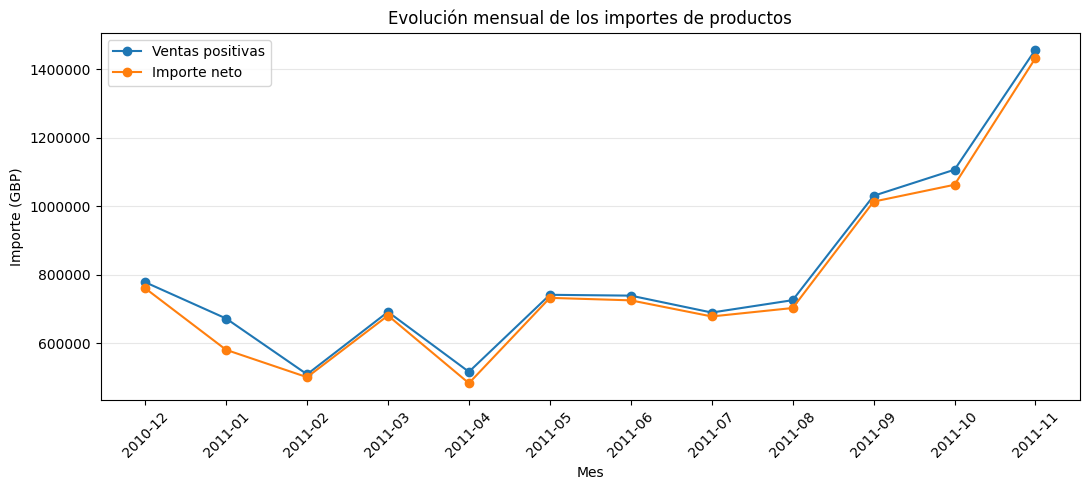

In [7]:
import matplotlib.pyplot as plt

movimientos = movimientos_productos.copy()
movimientos["Mes"] = movimientos["InvoiceDate"].dt.to_period("M")

ventas = ventas_positivas.copy()
ventas["Mes"] = ventas["InvoiceDate"].dt.to_period("M")

resumen_mensual = pd.DataFrame({
    "Ventas positivas": ventas.groupby("Mes")["Importe"].sum(),
    "Importe neto": movimientos.groupby("Mes")["Importe"].sum()
}).fillna(0)

# Mostramos todos los meses, incluido diciembre de 2011.
display(resumen_mensual.round(2))

# Comparamos solo los meses completos disponibles.
meses_completos = resumen_mensual.loc["2010-12":"2011-11"]

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(meses_completos.index.astype(str), meses_completos["Ventas positivas"], marker="o", label="Ventas positivas")
ax.plot(meses_completos.index.astype(str), meses_completos["Importe neto"], marker="o", label="Importe neto")

ax.set_title("Evolución mensual de los importes de productos")
ax.set_xlabel("Mes")
ax.set_ylabel("Importe (GBP)")
ax.ticklabel_format(axis="y", style="plain")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()
from pathlib import Path
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/monthly_amounts.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretación de la evolución mensual

Entre los meses completos disponibles, noviembre de 2011 presenta el mayor importe neto registrado, con £1.432.734,99. Abril de 2011 presenta el menor, con £482.901,21.

Se observa un aumento de los importes entre septiembre y noviembre de 2011. Este comportamiento podría estar relacionado con la demanda previa a las fiestas de fin de año, pero el período disponible no permite confirmar un patrón estacional recurrente.

En enero existe una diferencia marcada entre las ventas positivas y el importe neto. La cancelación de £77.183,60 identificada anteriormente contribuye a esa diferencia.

Diciembre de 2011 contiene datos únicamente hasta el día 9. Su menor importe acumulado no debe interpretarse como una caída frente a los meses completos.

## 8. Distribución del importe neto por país

Agrupamos los movimientos de productos según el país del cliente y sumamos sus importes, incluyendo los movimientos negativos.

El número de registros no equivale al valor de las ventas. Por eso, utilizamos el importe neto para comparar la contribución de cada país al total analizado.

Calculamos la participación de Reino Unido y mostramos por separado los diez países restantes con mayor importe neto.

,Importe neto (GBP),Participación (%)
Country,,
United Kingdom,8301718.28,84.77
Netherlands,283479.54,2.89
EIRE,259663.46,2.65
Germany,200808.40,2.05
France,182163.39,1.86
Australia,136990.00,1.40
Switzerland,52505.35,0.54
Spain,51765.20,0.53
Belgium,36662.96,0.37


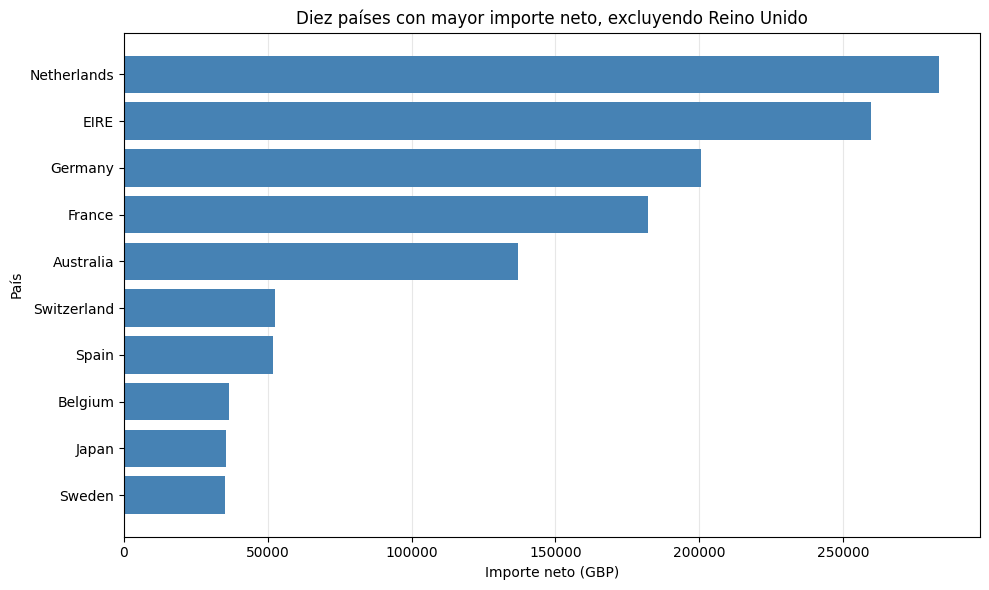

Participación de Reino Unido: 84.77%


In [8]:
importe_pais = movimientos_productos.groupby("Country")["Importe"].sum().sort_values(ascending=False)

resumen_paises = importe_pais.to_frame("Importe neto (GBP)")
resumen_paises["Participación (%)"] = 100 * importe_pais / importe_pais.sum()

display(resumen_paises.head(15).round(2))

participacion_reino_unido = resumen_paises.loc["United Kingdom", "Participación (%)"]
print(f"Participación de Reino Unido: {participacion_reino_unido:.2f}%")

# Separamos Reino Unido para observar mejor los otros países.
principales_paises = importe_pais.drop("United Kingdom").head(10).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(principales_paises.index, principales_paises.values, color="steelblue")

ax.set_title("Diez países con mayor importe neto, excluyendo Reino Unido")
ax.set_xlabel("Importe neto (GBP)")
ax.set_ylabel("País")
ax.ticklabel_format(axis="x", style="plain")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
from pathlib import Path
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/countries.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretación de la distribución por país

Reino Unido concentra el 84,77 % del importe neto de productos, con £8.301.718,28. El resto de los países representa aproximadamente el 15,23 %.

Los mayores importes fuera de Reino Unido corresponden a Países Bajos, Irlanda, Alemania y Francia.

Estos resultados muestran una fuerte concentración geográfica en el período analizado. Sin embargo, el importe por país no permite determinar cuántos clientes lo generan: una participación elevada podría proceder de numerosos compradores o de pocos clientes con pedidos grandes.

## 9. Productos con mayor importe neto

Agrupamos los movimientos por código de producto y calculamos su importe neto y sus unidades netas, incluyendo las cantidades negativas.

Utilizamos el código para identificar cada producto, porque su descripción puede variar entre registros. Para mostrar nombres legibles, seleccionamos la descripción no vacía más frecuente de cada código.

El importe neto permite comparar la contribución monetaria de los productos. No representa su rentabilidad, ya que el archivo no contiene sus costos.

,Importe_neto,Unidades_netas,Description,Participacion
StockCode,,,,
22423,164762.19,13022,REGENCY CAKESTAND 3 TIER,1.68
85123A,99846.98,35374,WHITE HANGING HEART T-LIGHT HOLDER,1.02
47566,98302.98,18018,PARTY BUNTING,1.00
85099B,92356.03,47359,JUMBO BAG RED RETROSPOT,0.94
23084,66756.59,30680,RABBIT NIGHT LIGHT,0.68
22086,63791.94,18902,PAPER CHAIN KIT 50'S CHRISTMAS,0.65
84879,58959.73,36381,ASSORTED COLOUR BIRD ORNAMENT,0.60
79321,53768.06,10226,CHILLI LIGHTS,0.55
22502,51041.37,1865,PICNIC BASKET WICKER SMALL,0.52


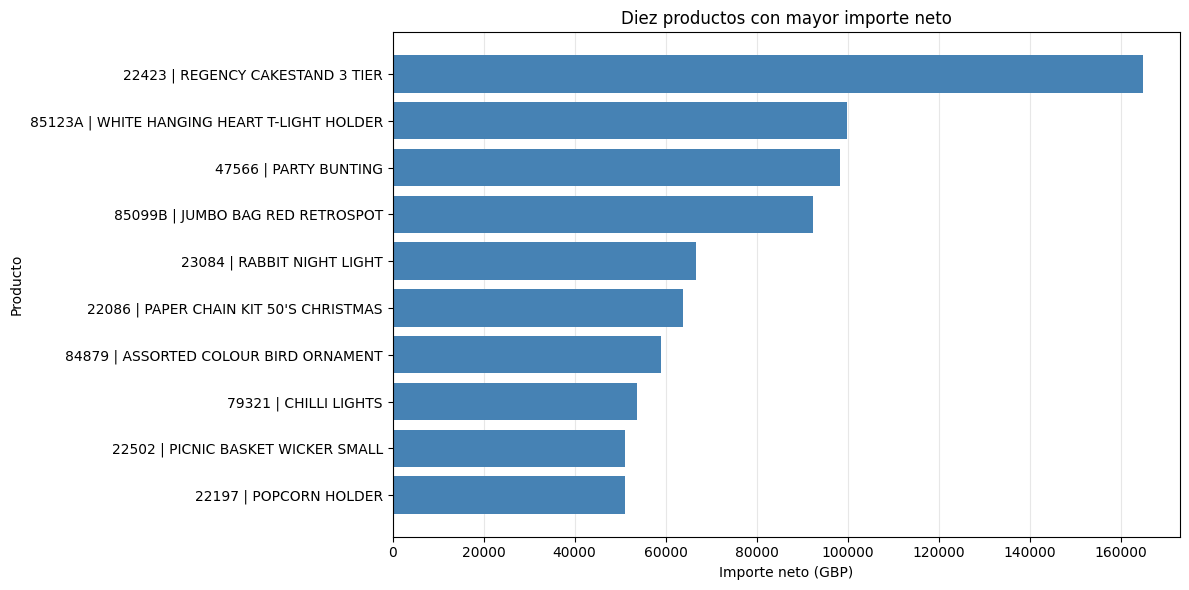

Participación conjunta de los diez productos principales:
8.18%


In [9]:
resumen_productos = movimientos_productos.groupby("StockCode").agg(
    Importe_neto=("Importe", "sum"),
    Unidades_netas=("Quantity", "sum")
)

# Elegimos la descripción más frecuente de cada producto.
descripciones = movimientos_productos[["StockCode", "Description"]].copy()
descripciones["Description"] = descripciones["Description"].astype("string").str.strip()
descripciones = descripciones.dropna(subset=["Description"])
descripciones = descripciones[descripciones["Description"] != ""]

frecuencias = descripciones.groupby(["StockCode", "Description"]).size().reset_index(name="Frecuencia")
frecuencias = frecuencias.sort_values(
    ["StockCode", "Frecuencia", "Description"],
    ascending=[True, False, True]
)

nombres = frecuencias.drop_duplicates("StockCode").set_index("StockCode")["Description"]

resumen_productos = resumen_productos.join(nombres)
resumen_productos["Description"] = resumen_productos["Description"].fillna("Sin descripción")
resumen_productos["Participacion"] = 100 * resumen_productos["Importe_neto"] / resumen_productos["Importe_neto"].sum()
resumen_productos = resumen_productos.sort_values("Importe_neto", ascending=False)

display(resumen_productos.head(10).round(2))

# Graficamos los diez productos con mayor importe neto.
principales_productos = resumen_productos.head(10).sort_values("Importe_neto")
etiquetas = principales_productos.index.astype(str) + " | " + principales_productos["Description"]

fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(etiquetas, principales_productos["Importe_neto"], color="steelblue")
ax.set_title("Diez productos con mayor importe neto")
ax.set_xlabel("Importe neto (GBP)")
ax.set_ylabel("Producto")
ax.ticklabel_format(axis="x", style="plain")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
from pathlib import Path
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/products.png", dpi=150, bbox_inches="tight")
plt.show()

print("Participación conjunta de los diez productos principales:")
print(f"{principales_productos['Participacion'].sum():.2f}%")

### Interpretación de los principales productos

El producto REGENCY CAKESTAND 3 TIER presenta el mayor importe neto registrado, con £164.762,19 y una participación del 1,68 %.

Los diez productos con mayor importe neto representan aproximadamente el 8,18 % del total. Por tanto, la mayor parte del importe procede de productos que no aparecen en este ranking.

Un mayor importe no implica necesariamente una mayor cantidad vendida. Por ejemplo, POPCORN HOLDER acumula 56.450 unidades netas, frente a las 13.022 de REGENCY CAKESTAND 3 TIER, pero su contribución monetaria es menor.

Este ranking describe la contribución al importe neto dentro del período y los criterios seleccionados. No permite identificar los productos más rentables porque no contamos con sus costos.

## 10. Conclusiones y limitaciones

La revisión permitió distinguir movimientos de productos, cancelaciones y otros conceptos incluidos en el archivo original.

De los 541.909 registros iniciales, conservamos 536.465 movimientos de productos. Su importe neto registrado es de £9.792.708,88.

Los principales resultados son:

- Eliminar las repeticiones exactas reduce el importe neto un 0,22 %. Las conservamos en el análisis principal porque no podemos confirmar que sean errores.
- Las dos operaciones con mayores cantidades positivas tienen cancelaciones que compensan completamente sus importes.
- Noviembre de 2011 presenta el mayor importe neto entre los meses completos analizados.
- Reino Unido concentra el 84,77 % del importe neto.
- Los diez productos principales representan aproximadamente el 8,18 % del importe neto.

### Limitaciones

El análisis conserva movimientos sin identificación de cliente, por lo que los resultados generales no pueden trasladarse directamente a un estudio individual de compradores.

El período disponible no permite confirmar patrones estacionales recurrentes. Además, diciembre de 2011 solo contiene registros hasta el día 9.

Las cancelaciones se contabilizan en la fecha en que fueron registradas, que puede ser diferente de la fecha de la venta original.

Los importes corresponden a la selección de productos definida en este trabajo. No representan la contabilidad completa del negocio ni sus ganancias.

## 11. Exportación de resultados

Guardamos los movimientos seleccionados, los registros excluidos con sus indicadores y las tablas de resultados en CSV. Los gráficos también se guardan en `figures/`. El Excel original se conserva sin modificaciones.

In [10]:
from pathlib import Path

carpeta = Path("resultados")
carpeta.mkdir(exist_ok=True)

movimientos_productos.to_csv(carpeta / "movimientos_productos.csv", index=False)
registros_excluidos.to_csv(carpeta / "registros_excluidos.csv", index=False)

comparacion.to_csv(carpeta / "comparacion_duplicados.csv", index_label="Indicador")
resumen_mensual.to_csv(carpeta / "resumen_mensual.csv")
resumen_paises.to_csv(carpeta / "resumen_paises.csv")
resumen_productos.to_csv(carpeta / "resumen_productos.csv")

print("Resultados guardados en la carpeta resultados.")

Resultados guardados en la carpeta resultados.
